In [1]:
import numpy as np
import pandas as pd

# For statistical tests
from scipy import stats

# For visualization
import matplotlib.pyplot as plt
import seaborn as sns

# For text EDA
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

from sklearn.linear_model import LinearRegression, LogisticRegression

from sklearn.feature_selection import VarianceThreshold

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, average_precision_score


from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from catboost import CatBoostClassifier
import lightgbm as lgb
from sklearn.metrics import roc_auc_score
import pandas as pd


# For entropy computation
from pyitlib import discrete_random_variable as drv

import lightgbm as lgb
from sklearn.metrics import roc_auc_score

In [2]:
### Load data

train_raw = pd.read_csv("train.csv", header = 0)
test_raw = pd.read_csv("test.csv", header = 0)
edges_raw = pd.read_csv("txs_edgelist.csv", header = 0)
sample_submission = pd.read_csv("sample_submission.csv", header = 0)

In [3]:
### Preview Data

print("train data:\n",train_raw.head(10), "\n")

print("test data:\n", test_raw.head(10), "\n")

# From Kaggle Page, edges is optional to use
print("edges:\n", edges_raw.head(10), "\n")

train data:
         txId  time_step    feat_1    feat_2    feat_3     feat_4    feat_5  \
0  230425980          1 -0.171469 -0.184668 -1.201369  -0.121970 -0.043875   
1    5530458          1 -0.171484 -0.184668 -1.201369  -0.121970 -0.043875   
2  232022460          1 -0.172107 -0.184668 -1.201369  -0.121970 -0.043875   
3  232438397          1  0.163054  1.963790 -0.646376  12.409294 -0.063725   
4  230460314          1  1.011523 -0.081127 -1.201369   1.153668  0.333276   
5  230459870          1  0.961040 -0.081127 -1.201369   1.303743  0.333276   
6  230333930          1 -0.171264 -0.184668 -1.201369  -0.121970 -0.043875   
7  230595899          1 -0.171755 -0.184668 -1.201369  -0.046932 -0.043875   
8  232013274          1 -0.123127 -0.184668 -1.201369  -0.121970 -0.043875   
9  232029206          1 -0.005027  0.578941 -0.091383   4.380281 -0.063725   

     feat_6     feat_7    feat_8  ...  feat_157  feat_158  feat_159  feat_160  \
0 -0.113002  -0.061584 -0.162097  ... -0.600999

In [4]:
### Check which columns have NAs
train_raw.columns[train_raw.isna().any()].tolist()

['label']

## 2.1 Data Preprocessing and Feature Engineering

### Data Cleaning and Transformation
* **Data Cleaning & Preparation:** Describe how the data was cleaned, transformed, and prepared.
* **Handling Missing Values:** Detail decisions and methods used for handling missing values, justified by domain insights or experimental evidence.

### Feature Engineering
* **Graph-Based Features:** 
  * Node degree
  * Neighborhood aggregates
  * Other engineered graph features
* **Justification:** Justify the graph-based choices using domain insights or experimental evidence.

---

### Feature Selection, Extraction, and Augmentation
* **Feature Selection & Extraction:** Outline the methods and criteria applied for selecting and extracting features.
* **Augmentation Techniques:** Detail any data augmentation techniques used.
* **Justification:** Provide domain insights or experimental evidence justifying these decisions.

In [5]:
### Edgelist - is optional use, leave to the back burner for now

print("check for self-payments:", len(edges_raw[edges_raw["txId1"] == edges_raw["txId2"]]))

check = edges_raw.groupby(by = ["txId1", "txId2"], as_index = False).size()

print(check)

check for self-payments: 0
            txId1      txId2  size
0            1076      10254     1
1            2534    8939825     1
2            2534  121654946     1
3            2534  121674867     1
4            3181   14630122     1
...           ...        ...   ...
234350  403198336  139318803     1
234351  403198336  147296550     1
234352  403203785  264780574     1
234353  403244581  139456179     1
234354  403244581  159227581     1

[234355 rows x 3 columns]


In [6]:
edges = edges_raw.drop_duplicates(subset=['txId1', 'txId2'])
edges = edges[edges['txId1'] != edges['txId2']]

in_deg = edges['txId2'].value_counts()
out_deg = edges['txId1'].value_counts()

# 3. Attach Graph + Volume features directly to train_raw and test_raw
for df in [train_raw, test_raw]:
    df['in_degree'] = df['txId'].map(in_deg).fillna(0).astype('float32')
    df['out_degree'] = df['txId'].map(out_deg).fillna(0).astype('float32')
    df['total_degree'] = df['in_degree'] + df['out_degree']
    df['degree_ratio'] = (df['in_degree'] + 1.0) / (df['out_degree'] + 1.0)
    
    # Total transaction volume per time_step across the whole network
    step_vol = df['time_step'].value_counts()
    df['timestep_tx_volume'] = df['time_step'].map(step_vol).astype('float32')

print("train_raw shape with graph features:", train_raw.shape)
print("test_raw shape with graph features:", test_raw.shape)

train_raw shape with graph features: (141772, 173)
test_raw shape with graph features: (15329, 173)


In [7]:
### Train/Test:
### Assessment of NA values - label

'''
feature_1 … feature_165 — anonymized, pre-normalized numeric features describing each transaction. These fall into two broad groups, though the exact identity of each column is not disclosed:
Local features: information about the transaction itself (e.g. transaction volume, fee, number of inputs/outputs).
Aggregated features: statistics (max, min, standard deviation, correlation, etc.) computed over the transaction's immediate neighbors in the graph.
'''

train_labeled = train_raw[train_raw['label'].isin([0.0, 1.0])].copy()
train_labeled['label'] = train_labeled['label'].astype(int)

train_unlabeled = train_raw[train_raw['label'].isna()].copy()

print(f"Total train rows: {len(train_raw)}")
print(f"Usable labeled rows for training: {len(train_labeled)} ({len(train_labeled)*100/len(train_raw):.2f}%)")
print(f"Unlabeled rows (unusable for supervised training): {len(train_unlabeled)} ({len(train_unlabeled)*100/len(train_raw):.2f}%)")

class_counts = train_labeled['label'].value_counts()
illicit_pct = (class_counts[1] / len(train_labeled)) * 100

print(f"Licit (0): {class_counts[0]} | Illicit (1): {class_counts[1]} ({illicit_pct:.2f}% illicit)")

Total train rows: 141772
Usable labeled rows for training: 31235 (22.03%)
Unlabeled rows (unusable for supervised training): 110537 (77.97%)
Licit (0): 27591 | Illicit (1): 3644 (11.67% illicit)


As there is a high number of NA data (~77% of all provided training data),

I plan to use semi supervised learning. I will train a model on the existing labelled data, and then use it to label the NA data, and then train another model on it

label_group  -1.0   0.0   1.0
time_step                    
1            5733  2130    17
2            3427  1099    18
3            5342  1268    11
4            4253  1410    30
5            4921  1874     8
6            3843   480     5
7            4845  1101   102
8            3292  1098    67
9            4218   530   248
10           5755   954    18
11           3600   565   131
12           1541   490    16
13           3719   518   291
14           1605   374    43
15           3021   471   147
16           2445   402   128
17           2574   712    99
18           1587   337    52
19           2761   665    80
20           3391   640   260
21           2896   541   100
22           4131  1605   158
23           2978  1134    53
24           3466   989   137
25           1720   476   118
26           2006   421    96
27            883   182    24
28           1369   199    85
29           3101   845   329
30           1959   441    83
31           2106   604   106
32        

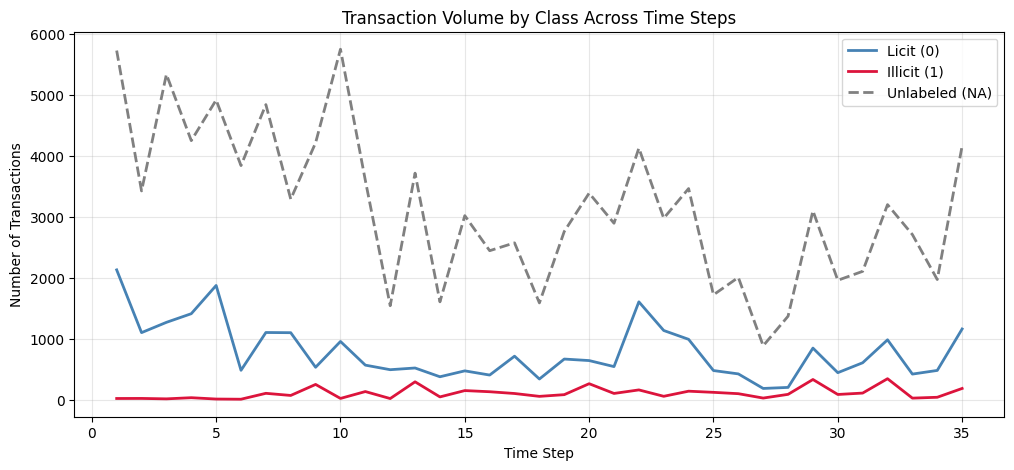

In [8]:
# Fill NaN with -1 temporarily so groupby includes missing labels as a column
time_label = (
    train_raw.assign(label_group=train_raw['label'].fillna(-1))
    .groupby(['time_step', 'label_group'])
    .size()
    .unstack(fill_value=0)
)

print(time_label)

plt.figure(figsize=(12, 5))
plt.plot(time_label.index, time_label[0.0], label='Licit (0)', color='steelblue', linewidth=2)
plt.plot(time_label.index, time_label[1.0], label='Illicit (1)', color='crimson', linewidth=2)
plt.plot(time_label.index, time_label[-1.0], label='Unlabeled (NA)', color='grey', linewidth=2, linestyle='--')

plt.title('Transaction Volume by Class Across Time Steps')
plt.xlabel('Time Step')
plt.ylabel('Number of Transactions')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Feature Engineering
* Remove features with near-zero variance (provides no useful information)
* Remove highly correlated features (keep only one)

In [8]:
feat_cols = [f'feat_{i}' for i in range(1, 166)]

# Calculate variance strictly on training data (to prevent data leakage)
variances = train_labeled[feat_cols].var()
low_var_cols = variances[variances < 1e-4].index.tolist()

print(f"Number of near-zero variance features (< 0.0001): {len(low_var_cols)}")
print("Columns:", low_var_cols)

Number of near-zero variance features (< 0.0001): 1
Columns: ['feat_15']


In [9]:
# 1. Compute absolute correlation matrix on labeled training features
corr_matrix = train_labeled[feat_cols].corr().abs()

# 2. Compute how strongly each feature correlates with the target 'label'
target_corr = train_labeled[feat_cols].apply(lambda x: x.corr(train_labeled['label'])).abs()
#print(type(target_corr))

# 3. Inspect only the upper triangle of the correlation matrix (to avoid checking pairs twice)
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
#print(upper_tri)

# 4. Find pairs with correlation > 0.95 and drop the weaker feature
threshold = 0.95
cols_to_drop = set()

for col in upper_tri.columns:
    # For every column, check through the rows if there is 1 row that > threshold => collect index (name)
    high_corr_partners = upper_tri.index[upper_tri[col] > threshold].tolist()
    
    for partner in high_corr_partners:
        if col not in cols_to_drop and partner not in cols_to_drop:
            #if col or partner is alr slated to drop - dont need to continue

            # Keep the feature that has a higher correlation with the target label
            if target_corr[col] < target_corr[partner]:
                cols_to_drop.add(col)
            else:
                cols_to_drop.add(partner)

cols_to_drop = sorted(list(cols_to_drop))
print(f"Found {len(cols_to_drop)} redundant features with correlation > {threshold}")
print("Features to drop:", cols_to_drop)

# 5. Create reduced feature list for modeling
selected_features = [c for c in feat_cols if c not in cols_to_drop]
print(f"Original features: {len(feat_cols)} -> Remaining features: {len(selected_features)}")

Found 61 redundant features with correlation > 0.95
Features to drop: ['feat_101', 'feat_104', 'feat_111', 'feat_116', 'feat_122', 'feat_128', 'feat_13', 'feat_133', 'feat_135', 'feat_139', 'feat_14', 'feat_140', 'feat_146', 'feat_152', 'feat_159', 'feat_165', 'feat_17', 'feat_21', 'feat_26', 'feat_27', 'feat_28', 'feat_29', 'feat_30', 'feat_31', 'feat_33', 'feat_34', 'feat_37', 'feat_39', 'feat_40', 'feat_43', 'feat_44', 'feat_46', 'feat_49', 'feat_51', 'feat_57', 'feat_58', 'feat_6', 'feat_60', 'feat_61', 'feat_62', 'feat_65', 'feat_66', 'feat_67', 'feat_68', 'feat_69', 'feat_72', 'feat_73', 'feat_74', 'feat_78', 'feat_79', 'feat_8', 'feat_81', 'feat_82', 'feat_84', 'feat_85', 'feat_86', 'feat_87', 'feat_9', 'feat_92', 'feat_94', 'feat_99']
Original features: 165 -> Remaining features: 104


In [10]:
### Drop unecessary variables

train_labeled = train_labeled.drop(columns = low_var_cols+cols_to_drop)
train_raw = train_raw.drop(columns = low_var_cols+cols_to_drop)
test_raw = test_raw.drop(columns = low_var_cols+cols_to_drop)

In [11]:
print(train_labeled.columns.tolist())

['txId', 'time_step', 'feat_1', 'feat_2', 'feat_3', 'feat_4', 'feat_5', 'feat_7', 'feat_10', 'feat_11', 'feat_12', 'feat_16', 'feat_18', 'feat_19', 'feat_20', 'feat_22', 'feat_23', 'feat_24', 'feat_25', 'feat_32', 'feat_35', 'feat_36', 'feat_38', 'feat_41', 'feat_42', 'feat_45', 'feat_47', 'feat_48', 'feat_50', 'feat_52', 'feat_53', 'feat_54', 'feat_55', 'feat_56', 'feat_59', 'feat_63', 'feat_64', 'feat_70', 'feat_71', 'feat_75', 'feat_76', 'feat_77', 'feat_80', 'feat_83', 'feat_88', 'feat_89', 'feat_90', 'feat_91', 'feat_93', 'feat_95', 'feat_96', 'feat_97', 'feat_98', 'feat_100', 'feat_102', 'feat_103', 'feat_105', 'feat_106', 'feat_107', 'feat_108', 'feat_109', 'feat_110', 'feat_112', 'feat_113', 'feat_114', 'feat_115', 'feat_117', 'feat_118', 'feat_119', 'feat_120', 'feat_121', 'feat_123', 'feat_124', 'feat_125', 'feat_126', 'feat_127', 'feat_129', 'feat_130', 'feat_131', 'feat_132', 'feat_134', 'feat_136', 'feat_137', 'feat_138', 'feat_141', 'feat_142', 'feat_143', 'feat_144', 'fe

Section 2.2
* Evaluate performance on NA data labelling
* class imbalance - assessment of illicit transactions per block

In [ ]:
df_eval = train_labeled.copy()

#set time block to be 5

df_eval["time_block"] = (
    (df_eval["time_step"] - 1) // 5 + 1
).astype(int)

print(
    df_eval.groupby("time_block")["label"]
    .agg(rows="size", illicit="sum")
)

            rows  illicit
time_block               
1           7865       84
2           4603      440
3           3046      628
4           3375      619
5           5311      566
6           2705      617
7           4330      690


In [ ]:
def make_masked_label_split(df, validation_fraction, seed):
    rng = np.random.default_rng(seed)
    validation_indices = []

    for _, group in df.groupby(["time_block", "label"]):
        # samples through each label for each time block - equally take ~20% where possible 
        indices = group.index.to_numpy()

        # Keep at least one example in training for this block/class
        if len(indices) < 2:
            continue

        # selects number of validation (test) datasets - fraction can be eg. 20%
        n_validation = max(1, round(len(indices) * validation_fraction))
        n_validation = min(n_validation, len(indices) - 1)

        validation_indices.extend(
            rng.choice(indices, size=n_validation, replace=False)
        )

    validation_indices = np.asarray(validation_indices)
    validation = df.loc[validation_indices]
    training = df.drop(index=validation_indices)

    return training, validation

In [ ]:
### Block 1

t_df, v_df = make_masked_label_split(df_eval, validation_fraction = 0.2, seed = 42)

print(len(v_df[v_df["label"] == 1]))